<a href="https://colab.research.google.com/github/leejsya/MLProgramming/blob/main/week6/DL_Abalone_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#### Library & Module Import

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### Preprocessing

In [ ]:
df = pd.read_csv("./Data/abalone.csv")
df.head()

,id,Sex,Length,Diameter,Height,Whole_weight,Shucked_weight,Viscera_weight,Shell_weight,Rings
0,0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [ ]:
# 결측값 확인
df.isna().sum()

id                0
Sex               0
Length            0
Diameter          0
Height            0
Whole_weight      0
Shucked_weight    0
Viscera_weight    0
Shell_weight      0
Rings             0
dtype: int64

In [ ]:
df = df[(df['Height'] > 0) & (df['Height'] < 0.5)]

In [ ]:
df = pd.get_dummies(df, columns=['Sex'], dtype='float32')

In [ ]:
len(df.columns)

12

In [ ]:
# input, target 설정
X = df.drop('Rings', axis=1).to_numpy().astype(np.float32)
y = df['Rings'].to_numpy().astype(np.float32)

In [ ]:
# 시드 고정
seed = 42

# 6 : 2 : 2로 train/val/test 분할
X_temp, X_test, y_temp, y_test = train_test_split(X, y,
                                                test_size=0.2,
                                                random_state=seed)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp,
                                                test_size=0.25,
                                                random_state=seed)


In [ ]:
# Standardization
scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

#### Dataset

In [ ]:
class AbaloneDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        X_tensor = torch.tensor(self.X[index], dtype=torch.float32)
        y_tensor = torch.tensor(self.y[index], dtype=torch.float32)

        return X_tensor, y_tensor


train_dataset = AbaloneDataset(X_train_scaled, y_train)
val_dataset = AbaloneDataset(X_val_scaled, y_val)
test_dataset = AbaloneDataset(X_test_scaled, y_test)

#### DataLoader

In [ ]:
torch.manual_seed(seed)
train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=32,
    shuffle=True,
    drop_last=True
)
val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=32,
)
test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=32,
)

#### Model

In [ ]:
class AbaloneModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(11, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 8)
        self.fc4 = nn.Linear(8, 1)
        self.dropout = nn.Dropout()
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc4(x)
        return x

#### Setup

In [ ]:
model = AbaloneModel()
loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [ ]:
device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
model.to(device)
print(device)

mps


#### Validation & Test function

In [ ]:
def evaluate(dataloader, model, loss_fn):
    model.eval()
    # loss값을 저장하는 리스트
    losses = []
    # 모든 예측값 리스트
    all_preds = []
    # 모든 타겟값 리스트
    all_targets = []
    with torch.no_grad():
        for batch in dataloader:
            inputs, targets = batch[0].to(device), batch[1].to(device)
            preds = model(inputs).squeeze(-1)
            loss = loss_fn(preds, targets)
            # loss 벡터의 각 요소를 losses 리스트에 넣음.
            losses.append(loss.item())

            # 각 배치의 예측값 텐서의 각 요소를 리스트에 저장
            all_preds.extend(preds.cpu().numpy())
            # 각 배치의 라벨값 텐서의 각 요소를 리스트에 저장
            all_targets.extend(targets.cpu().numpy())

    avg_loss = sum(losses) / len(losses)

    return avg_loss, all_preds, all_targets

#### Train Loop function

In [ ]:
def Train_Loop(dataloader, model, loss_fn, epochs, optimizer, min_loss):
    step = 0
    # 각 배치의 평균 loss값을 저장하는 리스트
    train_loss_history = []
    val_loss_history = []
    model.train()
    for epoch in range(epochs):
        for batch in dataloader:
            inputs, targets = batch[0].to(device), batch[1].to(device)
            preds = model(inputs).squeeze(-1)
            loss = loss_fn(preds, targets)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            step += 1
            if step % 10 == 0:
                print(f"(step {step}) train loss: {loss.item():.4f}")

            # train loss값 저장
            losses = []
            losses.append(loss.item())
        # 평균 train loss값 추가
        train_loss_history.append(np.mean(losses))

        val_loss, all_preds, all_targets = evaluate(
            val_dataloader,
            model,
            loss_fn
        )
        # 평균 validation loss값 추가
        val_loss_history.append(val_loss)
        print(f"[epoch {epoch+1}/{epochs}] val loss: {val_loss:.4f}\n")

        # val_loss가 가장 작을 때의 모델을 저장
        if min_loss >= val_loss:
            min_loss = val_loss
            torch.save(model.state_dict(), 'State_Dict/model4.pt')

    return min_loss, val_loss_history, train_loss_history, all_preds, all_targets

#### Training

In [ ]:
# min_loss를 무한한 양의 실수로 초기화
min_loss = float('inf')

# epochs=30으로 모델 training
min_loss, val_loss_history, train_loss_history, all_preds, all_targets = Train_Loop(
    train_dataloader,
    model,
    loss_fn,
    epochs=30,
    optimizer=optimizer,
    min_loss=min_loss,
)

(step 10) train loss: 90.9035
(step 20) train loss: 45.7334
(step 30) train loss: 43.2052
(step 40) train loss: 20.0954
(step 50) train loss: 34.5810
(step 60) train loss: 39.9109
(step 70) train loss: 20.5397
[epoch 1/30] val loss: 9.1628

(step 80) train loss: 12.2065
(step 90) train loss: 6.7930
(step 100) train loss: 2.7516
(step 110) train loss: 4.4655
(step 120) train loss: 4.6912
(step 130) train loss: 3.9958
(step 140) train loss: 3.3610
(step 150) train loss: 9.2927
[epoch 2/30] val loss: 4.8850

(step 160) train loss: 5.4504
(step 170) train loss: 1.8667
(step 180) train loss: 2.3894
(step 190) train loss: 8.4335
(step 200) train loss: 4.8812
(step 210) train loss: 3.6743
(step 220) train loss: 4.4467
(step 230) train loss: 2.5622
[epoch 3/30] val loss: 4.8810

(step 240) train loss: 2.5881
(step 250) train loss: 3.8954
(step 260) train loss: 4.0796
(step 270) train loss: 7.1080
(step 280) train loss: 7.4191
(step 290) train loss: 3.6393
(step 300) train loss: 5.5244
(step 31

#### Test

In [ ]:
# best model 생성
best_model = AbaloneModel().to(device)
# 성능이 가장 좋았을 때의 상태를 best_model에 대입
best_model.load_state_dict(torch.load('State_Dict/model4.pt'))
test_loss, _, _ = evaluate(
    test_dataloader,
    best_model,
    loss_fn
)
print(f"test loss: {test_loss:.4f}")

test loss: 4.4039


#### Metrics

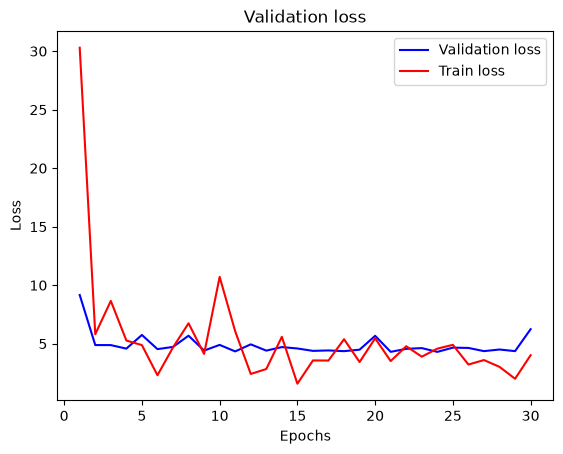

In [ ]:
# 학습 중 epoch에 따라 loss의 변화를 기록하여 나타낸 그래프
plt.plot(range(1, len(val_loss_history)+1), val_loss_history, 'b', label="Validation loss")
plt.plot(range(1, len(train_loss_history)+1), train_loss_history, 'r', label="Train loss")
plt.title("Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

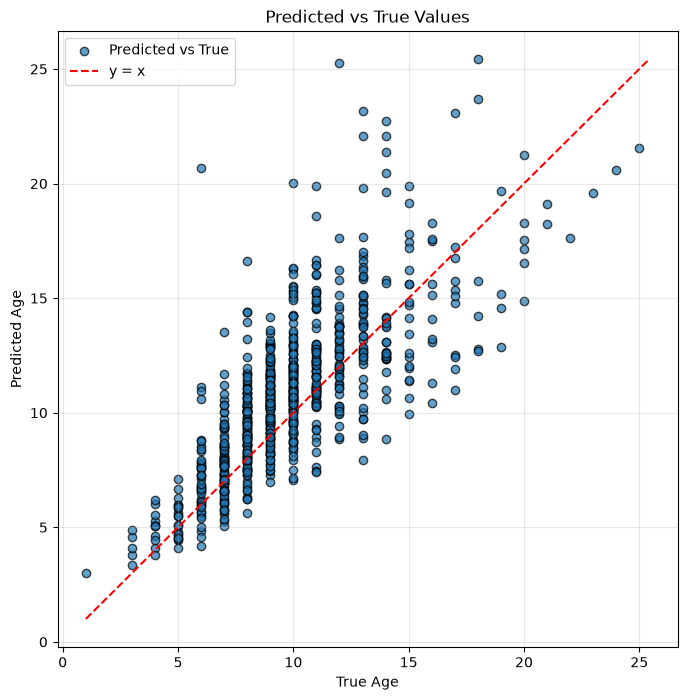

In [ ]:
# 예측결과를 산점도로 표현
plt.figure(figsize=(8,8))
plt.scatter(all_targets, all_preds, alpha=0.7, label="Predicted vs True", edgecolor='k')

min_val = min(min(all_targets), min(all_preds))
max_val = max(max(all_targets), max(all_preds))
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label='y = x')

plt.title('Predicted vs True Values')
plt.xlabel('True Age')
plt.ylabel('Predicted Age')
plt.legend()
plt.grid(alpha=0.3)
plt.show()